# Incremental DBSCAN cho dữ liệu SKU

Thuật toán phân cụm, cập nhật lân cận và các chỉ số đánh giá triển khai trong `incremental_dbscan.py` bằng NumPy. Không sử dụng thư viện DBSCAN, KFold hay các metric của scikit-learn. Notebook dùng `sku_clean_scaled.xlsx` và `Stream_order` để mô phỏng các batch đến theo thứ tự. `min_samples` **bao gồm chính điểm đang xét**.

Sáu biến liên tục đã scale được dùng trực tiếp. `Expire_group` được one-hot với khoảng cách giữa hai nhóm khác nhau bằng 1. Các cột ID, cờ ngoại lệ, thông tin luồng và các cờ zero chỉ dùng để đối chiếu, không tham gia tính khoảng cách.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from incremental_dbscan import (IncrementalDBSCAN, prepare_features,
                                evaluate_clustering, adjusted_rand_index)

DATA_PATH = Path('sku_clean_scaled.xlsx')
df = pd.read_excel(DATA_PATH).sort_values('Stream_order').reset_index(drop=True)
assert df['Stream_order'].tolist() == list(range(len(df)))
assert df['ID'].is_unique and not df.isna().any().any()
X = prepare_features(df, category_weight=1.0)
initial_n = int(0.70 * len(df))
X_initial = X[:initial_n]
update_batches = np.array_split(np.arange(initial_n, len(df)), 3)
print(f'Tổng: {len(df)} SKU; ban đầu: {initial_n}; batch cập nhật: {[len(b) for b in update_batches]}')
print(f'Số chiều đặc trưng: {X.shape[1]}')

Tổng: 2073 SKU; ban đầu: 1451; batch cập nhật: [208, 207, 207]
Số chiều đặc trưng: 10


## 1. Chọn cấu hình trên dữ liệu ban đầu

Chạy vòng lặp thủ công trên `eps` và `min_samples`, không dùng KFold. Mỗi cấu hình được `fit` trên cùng 70% đầu. Silhouette tính trên tối đa 600 điểm có nhãn cụm (mẫu ngẫu nhiên cố định để tiết kiệm thời gian), bỏ điểm nhiễu. Chỉ xét cấu hình có 2–30 cụm, tỷ lệ nhiễu tối đa 30% và cụm lớn nhất chiếm tối đa 80% các điểm đã phân cụm. Trong nhóm hợp lệ, tối đa hóa `silhouette × tỷ lệ được phân cụm`. Quy tắc này được định trước khi xem các batch cập nhật.

In [2]:
eps_grid = [0.35, 0.50, 0.65, 0.80, 1.00, 1.20, 1.50]
min_samples_grid = [5, 8, 12]
rows = []
for eps in eps_grid:
    for min_samples in min_samples_grid:
        candidate = IncrementalDBSCAN(eps=eps, min_samples=min_samples).fit(X_initial)
        metrics = evaluate_clustering(X_initial, candidate.labels_, silhouette_sample=600, seed=42)
        eligible = (2 <= metrics['n_clusters'] <= 30
                    and metrics['noise_ratio'] <= 0.30
                    and metrics['largest_cluster_share'] <= 0.80
                    and np.isfinite(metrics['silhouette']))
        rows.append({'eps': eps, 'min_samples': min_samples, **metrics,
                     'eligible': eligible,
                     'selection_score': metrics['silhouette'] * metrics['coverage'] if eligible else np.nan})
search_results = pd.DataFrame(rows).sort_values('selection_score', ascending=False, na_position='last')
if not search_results['eligible'].any():
    raise RuntimeError('Không có cấu hình đạt các ngưỡng chất lượng đã định; cần mở rộng lưới tham số.')
best_row = search_results.iloc[0]
best_estimator = IncrementalDBSCAN(eps=float(best_row['eps']),
                                   min_samples=int(best_row['min_samples'])).fit(X_initial)
display(search_results[['eps','min_samples','n_clusters','noise_ratio',
                        'largest_cluster_share','silhouette','selection_score','eligible']].round(4))
print('best_estimator:', best_estimator.get_params())

,eps,min_samples,n_clusters,noise_ratio,largest_cluster_share,silhouette,selection_score,eligible
8,0.65,12,17,0.2584,0.4870,0.3633,0.2694,True
11,0.80,12,13,0.1792,0.5584,0.3048,0.2502,True
14,1.00,12,6,0.1199,0.5544,0.2459,0.2164,True
6,0.65,5,26,0.1523,0.4423,0.2468,0.2092,True
7,0.65,8,18,0.2123,0.4619,0.2549,0.2008,True
10,0.80,8,17,0.1316,0.5278,0.2084,0.1810,True
9,0.80,5,17,0.1116,0.5175,0.1800,0.1599,True
13,1.00,8,7,0.0855,0.7543,0.0923,0.0844,True
12,1.00,5,10,0.0620,0.7428,0.0252,0.0236,True
0,0.35,5,43,0.3019,0.2419,0.4061,NaN,False


best_estimator: {'eps': 0.65, 'min_samples': 12}


## 2. Cập nhật dữ liệu theo ba batch

`partial_fit` thêm điểm mới, giữ toàn bộ điểm cũ và cập nhật lại quan hệ lân cận. Điểm cũ có thể từ nhiễu thành điểm biên/lõi; các cụm có thể nhập lại. Các chỉ số dưới đây phản ánh trạng thái **sau mỗi lần thêm batch**.

In [3]:
stages = []
initial_metrics = evaluate_clustering(X_initial, best_estimator.labels_, silhouette_sample=800)
stages.append({'stage': 'Ban đầu (70%)', **initial_metrics, **best_estimator.history_[-1]})
for batch_no, batch in enumerate(update_batches, start=1):
    best_estimator.partial_fit(X[batch])
    metrics = evaluate_clustering(X[:batch[-1]+1], best_estimator.labels_, silhouette_sample=800)
    stages.append({'stage': f'Batch {batch_no}', **metrics, **best_estimator.history_[-1]})
update_results = pd.DataFrame(stages)
display(update_results[['stage','n_seen','n_added','n_clusters','n_noise','noise_ratio',
                        'silhouette','davies_bouldin','calinski_harabasz',
                        'promoted_core','previous_noise_absorbed','old_cluster_ids_retired_by_merges']].round(4))

,stage,n_seen,n_added,n_clusters,n_noise,noise_ratio,silhouette,davies_bouldin,calinski_harabasz,promoted_core,previous_noise_absorbed,old_cluster_ids_retired_by_merges
0,Ban đầu (70%),1451,1451,17,375,0.2584,0.3650,0.7184,304.4880,0,0,0
1,Batch 1,1659,208,16,412,0.2483,0.3451,0.7585,311.3690,29,22,1
2,Batch 2,1866,207,16,430,0.2304,0.3551,0.7261,365.5307,38,21,1
3,Batch 3,2073,207,16,445,0.2147,0.3439,0.7300,408.1489,15,27,0


## 3. Đánh giá trên toàn bộ dữ liệu

Silhouette càng cao càng tốt; Davies–Bouldin càng thấp càng tốt; Calinski–Harabasz càng cao càng tốt. Ba chỉ số hình học chỉ tính trên điểm thuộc cụm; vì vậy cần đọc cùng tỷ lệ nhiễu và phân bố kích thước cụm. Cờ `Is_operational_outlier` là nhãn nghiệp vụ để tham khảo, không phải nhãn đúng cho DBSCAN.

In [4]:
final_metrics = evaluate_clustering(X, best_estimator.labels_, silhouette_sample=None)
cluster_sizes = pd.Series(best_estimator.labels_).value_counts().sort_index().rename_axis('cluster').reset_index(name='size')
cluster_sizes['share_all'] = cluster_sizes['size'] / len(df)
results = df[['ID','Stream_order','Is_operational_outlier']].copy()
results['cluster'] = best_estimator.labels_
results['is_core'] = best_estimator.core_mask_.astype(int)
results['is_noise'] = (best_estimator.labels_ == -1).astype(int)
outlier_cross = pd.crosstab(results['Is_operational_outlier'], results['is_noise'],
                           rownames=['Cờ outlier nghiệp vụ'], colnames=['Nhiễu DBSCAN'])
print('Chỉ số cuối:')
display(pd.Series(final_metrics).to_frame('value').round(4))
print('Kích thước cụm (-1 là nhiễu):')
display(cluster_sizes.round(4))
print('Đối chiếu cờ ngoại lệ:')
display(outlier_cross)
print('Ví dụ kết quả theo thứ tự luồng:')
display(results.head(10))

Chỉ số cuối:


,value
n_samples,2073.0000
n_clusters,16.0000
n_noise,445.0000
noise_ratio,0.2147
coverage,0.7853
largest_cluster_share,0.4785
silhouette,0.3455
davies_bouldin,0.7300
calinski_harabasz,408.1489


Kích thước cụm (-1 là nhiễu):


,cluster,size,share_all
0,-1,445,0.2147
1,0,779,0.3758
2,1,128,0.0617
3,2,211,0.1018
4,3,53,0.0256
5,4,92,0.0444
6,5,66,0.0318
7,7,23,0.0111
8,8,25,0.0121
9,9,24,0.0116


Đối chiếu cờ ngoại lệ:


Nhiễu DBSCAN,0,1
Cờ outlier nghiệp vụ,,
0,1535,383
1,93,62


Ví dụ kết quả theo thứ tự luồng:


,ID,Stream_order,Is_operational_outlier,cluster,is_core,is_noise
0,989,0,0,0,0,0
1,33,1,0,-1,0,1
2,1018,2,0,2,0,0
3,1653,3,0,0,1,0
4,540,4,0,1,1,0
5,2148,5,0,15,1,0
6,1107,6,0,0,1,0
7,1232,7,0,0,1,0
8,173,8,0,0,1,0
9,1330,9,0,-1,0,1


## 4. Trực quan hóa các cụm sau cập nhật

Chiếu toàn bộ không gian đặc trưng 10 chiều xuống các mặt phẳng PCA bằng SVD của NumPy. Màu biểu thị nhãn cụm cuối cùng, xám là nhiễu. PCA chỉ phục vụ hiển thị: DBSCAN và các chỉ số đánh giá vẫn dùng đủ 10 chiều. Điểm chồng lên nhau trong hình 2D có thể khác nhau ở các chiều còn lại.

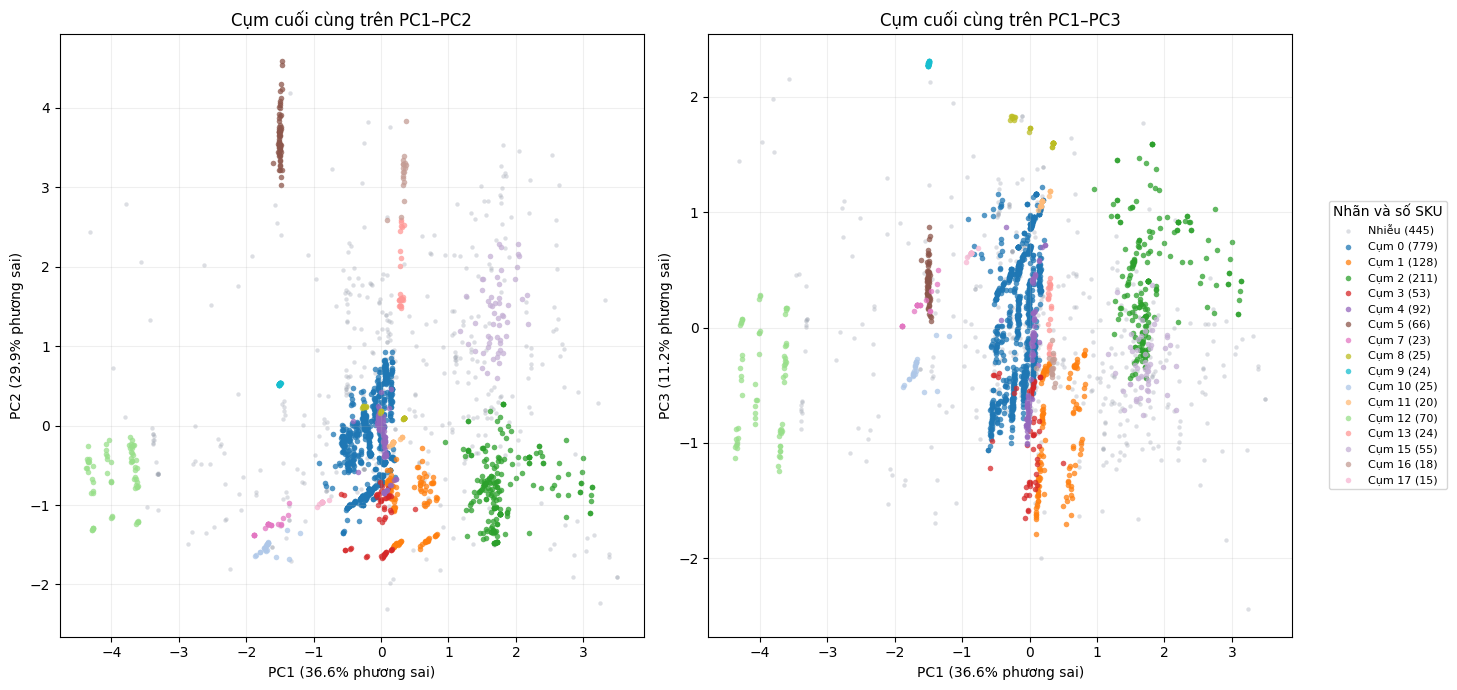

PC1 + PC2 giữ 66.5% phương sai; PC1 + PC2 + PC3 giữ 77.7%.


In [5]:
# PCA thủ công bằng SVD; không dùng thư viện phân cụm hoặc PCA.
X_centered = X - X.mean(axis=0)
_, singular_values, directions = np.linalg.svd(X_centered, full_matrices=False)
projected = X_centered @ directions[:3].T
explained = singular_values**2 / np.sum(singular_values**2)
labels = best_estimator.labels_
cluster_ids = sorted(set(labels) - {-1})
palette = plt.get_cmap('tab20')
palette_indices = [0, 2, 4, 6, 8, 10, 12, 16, 18, 1, 3, 5, 7, 9, 11, 13]
colors = [palette(i) for i in palette_indices]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (horizontal, vertical) in zip(axes, [(0, 1), (0, 2)]):
    noise = labels == -1
    ax.scatter(projected[noise, horizontal], projected[noise, vertical],
               s=10, c='#9ca3af', alpha=0.35, linewidths=0,
               label=f'Nhiễu ({noise.sum()})', rasterized=True)
    for color_index, cluster_id in enumerate(cluster_ids):
        mask = labels == cluster_id
        ax.scatter(projected[mask, horizontal], projected[mask, vertical],
                   s=16, color=colors[color_index], alpha=0.75, linewidths=0,
                   label=f'Cụm {cluster_id} ({mask.sum()})', rasterized=True)
    ax.set_xlabel(f'PC{horizontal+1} ({explained[horizontal]:.1%} phương sai)')
    ax.set_ylabel(f'PC{vertical+1} ({explained[vertical]:.1%} phương sai)')
    ax.grid(alpha=0.2)
axes[0].set_title('Cụm cuối cùng trên PC1–PC2')
axes[1].set_title('Cụm cuối cùng trên PC1–PC3')
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='center left', bbox_to_anchor=(0.83, 0.5),
           title='Nhãn và số SKU', fontsize=8)
fig.tight_layout(rect=(0, 0, 0.82, 1))
fig.savefig('clusters_pca.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'PC1 + PC2 giữ {explained[:2].sum():.1%} phương sai; '
      f'PC1 + PC2 + PC3 giữ {explained[:3].sum():.1%}.')

## 5. Kiểm tra tính đúng của cập nhật

Chạy lại chính thuật toán viết tay trên toàn bộ dữ liệu và so sánh với quá trình cập nhật. ID cụm có thể khác; Adjusted Rand Index (ARI) so sánh phân hoạch mà không phụ thuộc số ID. Điểm biên tiếp giáp nhiều cụm có thể được gán vào một trong các cụm hợp lệ, nên kiểm tra riêng điểm lõi và tập nhiễu.

In [6]:
fresh_estimator = IncrementalDBSCAN(**best_estimator.get_params()).fit(X)
core_agreement = np.array_equal(best_estimator.core_mask_, fresh_estimator.core_mask_)
noise_agreement = np.array_equal(best_estimator.labels_ == -1, fresh_estimator.labels_ == -1)
core_ari = adjusted_rand_index(best_estimator.labels_[best_estimator.core_mask_],
                               fresh_estimator.labels_[fresh_estimator.core_mask_])
all_ari = adjusted_rand_index(best_estimator.labels_, fresh_estimator.labels_)
print({'core_mask_equal': core_agreement,
       'noise_mask_equal': noise_agreement,
       'core_ARI': round(core_ari, 6),
       'all_points_ARI': round(all_ari, 6),
       'fresh_clusters': fresh_estimator.n_clusters_,
       'incremental_clusters': best_estimator.n_clusters_})
assert core_agreement and noise_agreement and np.isclose(core_ari, 1.0)

{'core_mask_equal': True, 'noise_mask_equal': True, 'core_ARI': 1.0, 'all_points_ARI': 1.0, 'fresh_clusters': 16, 'incremental_clusters': 16}


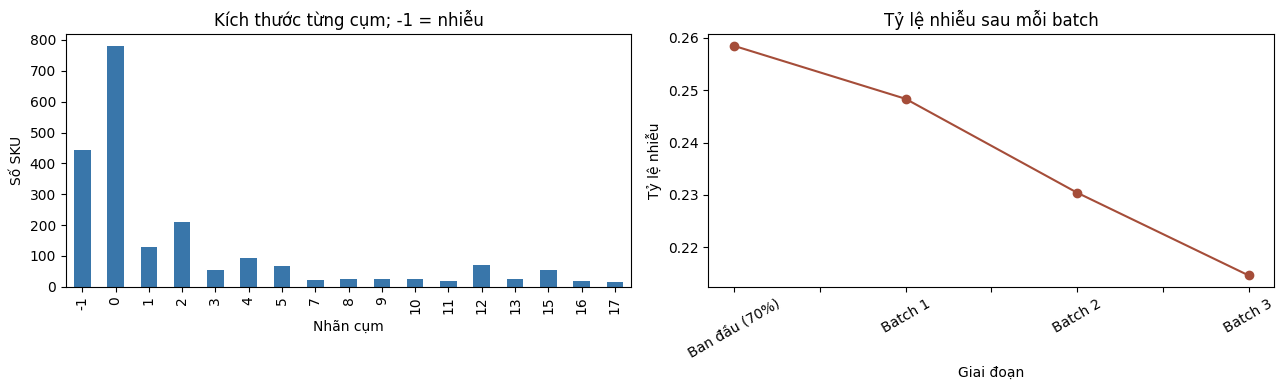

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cluster_sizes.plot.bar(x='cluster', y='size', ax=axes[0], legend=False, color='#3976aa')
axes[0].set_title('Kích thước từng cụm; -1 = nhiễu')
axes[0].set_xlabel('Nhãn cụm')
axes[0].set_ylabel('Số SKU')
update_results.plot(x='stage', y='noise_ratio', marker='o', ax=axes[1], color='#a54d39', legend=False)
axes[1].set_title('Tỷ lệ nhiễu sau mỗi batch')
axes[1].set_xlabel('Giai đoạn')
axes[1].set_ylabel('Tỷ lệ nhiễu')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## Ghi chú sử dụng

- `best_estimator` chứa mô hình sau khi nhận đủ ba batch; `results` chứa nhãn của từng SKU trong notebook.
- Có thể gọi `best_estimator.partial_fit(X_new)` khi **đã chuẩn hóa và mã hóa** dữ liệu mới theo đúng không gian đặc trưng hiện tại. File dữ liệu này không đi kèm tham số của bộ scaler gốc, nên notebook thử cập nhật bằng 30% mẫu giữ lại từ chính workbook.
- Thuật toán hỗ trợ **thêm** điểm và tham số `eps`, `min_samples` cố định. Xóa điểm hoặc đổi tham số cần `fit` lại. Cần lưu cả trạng thái mô hình (điểm và lân cận) để tiếp tục cập nhật ở phiên làm việc sau.